# Tutorial 2: an agent that drives the simulator

In the first tutorial **you** built a model, ran it and looked at the results. Here a program does those steps for you: you
give it a request in plain English, and it decides which `kusim` commands to run, reads the answers, fixes mistakes and
reports. The "brain" is a large language model (LLM) such as Mistral or Claude; everything else is ordinary Python that you can read.

By the end you will have:

1. built the **loop** (observe, act, check) that makes a program an *agent*, and run it on three tasks;
2. connected it to **any model** by changing three settings (or to a scripted model that needs no key);
3. **audited** what the agent did, and caught it claiming more than the data support.

**What you need.** The kusim package and the Python packages of tutorial 1. For a live model, a free API key (section 2). Without a key
the notebook runs a *scripted* model that makes the same tool calls a careful model makes, so you can do everything in this
notebook offline and get the same result every time.

**Cost and privacy.** Free plans have small quotas and some providers may use your prompts to train their models; everything here is
synthetic data, so nothing private leaves your computer. Never paste real company data into a free service.

**How an agent works.** It is a loop that repeats until the model gives an answer:

1. You give a task. The program sends the model the task, the list of tools and everything said so far. The model only ever sees text.
2. The model replies with either a final answer or a **tool call**, for example "call `run` with `model=model.json`".
3. The program checks the call, asks **you** first if it is expensive, runs `kusim run ...` and reads its JSON answer.
4. The answer, shortened, is added to the conversation, and the loop goes back to step 2.

The model never touches your files. It can only ask; the program decides what is allowed.

## 0. Set up

The helper modules are in this folder: `agent_lab.py` (the connection, the tools, the loop), `agent_lab_case.py` (the files the tasks work on) and `agent_lab_scripts.py` (the three requests and the scripted plans).

In [1]:
import importlib.util
import json
import os
import shutil
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

HERE = Path.cwd() if Path("agent_lab.py").exists() else Path("examples")      # this notebook's folder
sys.path.insert(0, str(HERE.resolve()))
import agent_lab as al
import agent_lab_case as case
import agent_lab_scripts as sc

for module in (al, case, sc):              # pick up a newer version of the helper files without restarting the kernel
    importlib.reload(module)

import kusim
print("kusim", kusim.__version__)

kusim 0.1.0


In [2]:
# a fresh folder for the agent to work in (the agent can not leave it), and the "hidden truth" next to it
shutil.rmtree(HERE / "output" / "agent_lab", ignore_errors=True)
folders = case.make_workspace(HERE / "output" / "agent_lab")
WORK = folders["work"]
for path in sorted(WORK.rglob("*")):
    if path.is_file():
        print(path.relative_to(WORK).as_posix())

field/history.csv
field/later.csv
field/parameters.json
field/prior.json
field/waterflood.DATA
field/waterflood_props.INC
model.json
model_b.json


`model.json` is for Task A, `model_b.json` for Task B and the folder `field/` for Task C: a deck, measured data with the field's well
names, and the description of what is uncertain. The real permeability that produced those data is kept in `hidden/`; the agent
has no tool that can read it, and we use it only at the end to check the agent's claims.

## 1. The tools: the command line, described to a model

A model can only use what it is told about. kusim was built so that every capability is a command with documented options and
one JSON answer, so the tool descriptions can be **generated** from the command line itself (`kusim.cli.build_parser()`). Add a command or
an option to kusim and the agent gets it.

In [3]:
tools, commands = al.kusim_tools()
rows = []
for t in tools:
    if t["name"] in commands:                                    # a kusim command: show the command and its options
        command, layout = commands[t["name"]]
        options = " ".join(flag or f"<{key}>" for key, flag, _, _ in layout)
        rows.append((t["name"], f"kusim {command}", options, t["description"][:95]))
    else:                                                        # list_files, read_file, write_file: Python helpers of the agent
        rows.append((t["name"], "(local helper, not a kusim command)", "", t["description"][:95]))
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows, columns=["tool", "command it runs", "options", "what the model is told"])

,tool,command it runs,options,what the model is told
0,template,kusim template,--output --nx --ny --nz --days,kusim template: write an example model (layered waterflood) to start from
1,import_deck,kusim import-deck,<deck> --output --schedule-out --wells-out --dt --pvt-pressures --skip-unknown,kusim import-deck: read an ECLIPSE-style deck (.DATA) into a JSON model and schedule
2,import_history,kusim import-history,<input> --output --controls-out --model --sheet --layout --header-row --start-date --dayfirst --dt --every --align --well-map --wells-file --vectors --pressure-unit --rate-unit --water-cut-unit --sigma --producer-control,kusim import-history: read historical well data from an Excel workbook or CSV into observations
3,validate,kusim validate,<model> --schedule --restart --fields,kusim validate: check a model (and a schedule) without running
4,edit,kusim edit,<model> --set --patch --output,kusim edit: change values of a model by path (producers.0.target=2500) and write it
5,diff,kusim diff,<a> <b>,"kusim diff: list what differs between two models, by path"
6,schema,kusim schema,<name>,kusim schema: print the JSON Schema of a file type
7,misfit,kusim misfit,<model> --observations --schedule --restart --upstream --out --strict,kusim misfit: run a model and compare it with observed data
8,gradient,kusim gradient,<model> --observations --parameters --controls --schedule --restart --x --method --check --upstream --out,kusim gradient: objective and gradient of the misfit (adjoint) with respect to parameters/contr
9,ensemble,kusim ensemble,<model> --method --observations --parameters --prior --schedule --members --seed --passes --alphas --localise --workers --out --write-members --write-ensemble --strict,kusim ensemble: history matching with an ensemble: ES-MDA or the EnKF


In [4]:
# what the model receives for one tool: a name, a description and a JSON Schema of the arguments
edit = next(t for t in tools if t["name"] == "edit")
print(json.dumps(edit, indent=1)[:1500])

{
 "name": "edit",
 "description": "kusim edit: change values of a model by path (producers.0.target=2500) and write it",
 "parameters": {
  "type": "object",
  "properties": {
   "model": {
    "type": "string",
    "description": "a file name in the workspace. "
   },
   "set": {
    "type": "array",
    "items": {
     "type": "string"
    },
    "description": "one change as PATH=VALUE, for example producers.0.target=2000 or dt=5 (the value is JSON or text); repeatable; list positions count from 0"
   },
   "patch": {
    "type": "string",
    "description": "a file name in the workspace. NAME OF A FILE (not inline JSON) holding an object merged into the model (lists are replaced); for single values use --set"
   },
   "output": {
    "type": "string",
    "description": "a file name in the workspace. file to write"
   }
  },
  "required": [
   "model"
  ]
 }
}


Three things are *not* in the list on purpose: the guardrail limits (`max_cells`, `max_seconds`, ... an agent may lower them, not
raise them), editing a model in place (an agent writes a new file), and a way out of the workspace folder. `ensemble` has caps
(at most 4 workers and 100 members here) and **waits for your approval**, because it runs many simulations.

## 2. Connect a model

All providers below speak the same "chat with tools" protocol, except Anthropic, which has its own; `agent_lab.connect()` hides the
difference. Choose with three environment variables, **set before you start Jupyter** (or in a cell, see below):

| Provider | `KUSIM_LLM_PROVIDER` | Key variable | Where to get a key |
|---|---|---|---|
| **Mistral** (the default) | `mistral` | `MISTRAL_API_KEY` | console.mistral.ai, the free "Experiment" plan |
| Groq | `groq` | `GROQ_API_KEY` | console.groq.com, free plan (limits are per model) |
| Anthropic | `anthropic` | `ANTHROPIC_API_KEY` | console.anthropic.com |
| OpenRouter | `openrouter` | `OPENROUTER_API_KEY` | openrouter.ai (some models are free) |
| Ollama (on your computer) | `ollama` | none | ollama.com; pull a model that supports tools |
| anything OpenAI-compatible | `custom` | `KUSIM_LLM_API_KEY` | also set `KUSIM_LLM_BASE_URL` and `KUSIM_LLM_MODEL` |
| no model | `scripted` | none | replays a plan |

`KUSIM_LLM_MODEL` picks another model of the provider (the defaults in `agent_lab.PRESETS` were right when written; providers retire
models and change free quotas often, so check the provider's page). In PowerShell: `$env:MISTRAL_API_KEY = "..."` then start `jupyter lab`.

In [5]:
# Optional: type a key for this session only (it is not saved in the notebook). Remove the '#' to use it.
# import getpass; os.environ["MISTRAL_API_KEY"] = getpass.getpass("Mistral key: ")

In [6]:
try:
    al.connect()                      # reads KUSIM_LLM_PROVIDER (default: mistral) and the key
    LIVE = True
    print("live model:", al.connect().model, "at", al.connect().base_url)
except al.LLMError as problem:
    LIVE = False
    print(problem)
    print("\n-> continuing with the scripted model: the same tool calls, no key needed.")


def new_agent(task, **kwargs):
    """An agent for 'A', 'B' or 'C': the live model if there is a key, else the scripted plan of that task."""
    llm = al.connect() if LIVE else al.connect("scripted", script=sc.SCRIPTS[task])
    (WORK / f"trace_{task}.jsonl").unlink(missing_ok=True)
    return al.Agent(llm, WORK, approve=al.ask_user if LIVE else al.auto_approve, trace=f"trace_{task}.jsonl", **kwargs)

no API key for mistral: this program looked for the environment variable MISTRAL_API_KEY (and KUSIM_LLM_API_KEY) and found neither. Get a key at https://console.mistral.ai (free 'Experiment' plan). A variable set in a terminal only reaches programs started AFTER it was set, from that same terminal: set it, start Jupyter (or VS Code) from that terminal, or restart the kernel if it was already running. Or put the line MISTRAL_API_KEY=... in a file named .env next to agent_lab.py, or type the key in the getpass cell of the notebook; or use provider 'scripted' to run without a model



-> continuing with the scripted model: the same tool calls, no key needed.


**Cannot connect? Check the network first.** If the cells above or below fail with a message about a web page, a reset connection, a certificate or a timeout, the cause is usually not your key but the network: a company firewall or web filter that blocks AI services, or one that inspects HTTPS traffic. `al.diagnose` asks the provider's server (without your key) and tells you whether it can be reached from this computer, and if not, what it saw instead (for example the block page text) and what to do about it: ask IT to allow the address, set `HTTPS_PROXY`, set `SSL_CERT_FILE` to the company certificate, try another network, or use the local notebook (Ollama) instead.

In [7]:
al.diagnose()

OK: https://api.mistral.ai/v1 answered with JSON (HTTP 401): the provider can be reached from this computer. (A 401 or 403 is expected here: no key was sent.)


True

**Say hello first.** Before any tools: can you talk to the model? The cell below sends a greeting and prints the answer. This only checks the connection (key, address, model name) and shows the reply, the time and the token count. Change `GREETING`, or call `talk("...")` again to keep the conversation going: the model remembers what was said before in `history`.
A model does not always know its own name, so trust the "live model" line above, not what the model says about itself.

In [8]:
import time

GREETING = "Hello! Who are you, and what can you help me with in a reservoir-simulation course?"     # change it, or call talk("...") yourself

llm = al.connect() if LIVE else None

history = [{"role": "system", "content": "You are a friendly assistant in a reservoir-simulation course. Answer in two or three sentences."}]


def talk(text):
    """Send one message, with the conversation so far, and print the model's answer."""
    history.append({"role": "user", "content": text})
    started = time.time()
    reply = llm.chat(history, [])                                   # no tools here: just a conversation
    history.append({"role": "assistant", "content": reply.text or "(no answer)"})
    print(f"you  : {text}\nmodel: {reply.text.strip() or '(an empty answer: try again, or check the model name)'}")
    print(f"({time.time() - started:.1f} s, tokens: {reply.usage})")


if LIVE:
    talk(GREETING)
else:
    print("(skipped: no live model; the scripted model does not talk)")

(skipped: no live model; the scripted model does not talk)


In [9]:
# one test call: does the model ask for a tool when we ask it to? (only with a live model)
if LIVE:
    llm = al.connect()
    answer = llm.chat([{"role": "user", "content": "Call the tool list_files once, with no arguments."}],
                      [t for t in tools if t["name"] == "list_files"])
    print("the model asked for:", [(c.name, c.arguments) for c in answer.tool_calls] or answer.text)
else:
    print("(skipped: no live model)")

(skipped: no live model)


## 3. You are the agent first

Before the loop, do what the loop does, by hand. `helper.call(tool, **arguments)` makes one tool call with the same checks the agent's calls get,
and returns the answer as a dict. Answers are long, so the agent sees a shortened form (`al.compact`): long lists cut, floats
rounded, the keys that matter (`ok`, `error`, `code`, `hint`) first.

In [10]:
helper = al.Agent(al.connect("scripted"), WORK, verbose=False)
answer = helper.call("validate", model="model.json")
print("validate -> runnable:", answer["runnable"], "| findings:", answer["checks"]["findings"])

validate -> runnable: True | findings: []


In [11]:
# a mistake on purpose: an unknown option is refused BEFORE anything runs, and the answer says what is allowed
print(al.compact(helper.call("edit", model="model.json", rate=300, output="x.json"), 400))
# and a wrong path inside the model: kusim's own error is located and has hints
print(al.compact(helper.call("edit", model="model.json", set=["producers.0.tarjet=2000"], output="x.json"), 500))

{"ok":false,"error":"unknown argument(s) ['rate']; this tool takes ['model', 'output', 'patch', 'set'] (nothing was run)","code":"invalid_arguments"}


{"ok":false,"error":"the edit is not valid: a well in 'producers': unknown key(s) ['tarjet']; allowed keys are ['block', 'min_bhp', 'min_oil_rate', 'mode', 'radius', 'skin', 'target', 'wellbore_gravity']","code":"unknown_key","path":"producers.0.tarjet","did_you_mean":{"tarjet":"target"},"allowed":["block","min_bhp","min_oil_rate","mode","radius","skin","target","wellbore_gravity"]}


In [12]:
helper.call("edit", model="model.json", set=["producers.0.target=2300"], output="by_hand.json")
answer = helper.call("run", model="by_hand.json", out="runs/by_hand")
p1 = answer["wells"]["P1"]
print(f"healthy: {answer['healthy']} | P1 after {answer['final_time']:g} days: oil rate {p1['oil_rate']:.1f} STB/d, cumulative oil {p1['cum_oil']:,.0f} STB")

healthy: True | P1 after 1000 days: oil rate 53.3 STB/d, cumulative oil 107,980 STB


Now the same thing as a **loop**. This is the whole idea in about 15 lines (the real `Agent.run` adds the checks, the approval, the trace and the step limit):

In [13]:
def tiny_agent(llm, task, helper, max_steps=8):
    messages = [{"role": "system", "content": al.SYSTEM_PROMPT}, {"role": "user", "content": task}]
    for _ in range(max_steps):
        reply = llm.chat(messages, helper.tools)                      # 1. the model looks and decides
        if not reply.tool_calls:
            return reply.text                                          #    no tool wanted: it answers
        messages.append({"role": "assistant", "content": reply.text or None, "tool_calls": [
            {"id": c.id, "type": "function", "function": {"name": c.name, "arguments": json.dumps(c.arguments)}} for c in reply.tool_calls]})
        for call in reply.tool_calls:
            result = helper.call(call.name, **call.arguments)         # 2. the program acts
            messages.append({"role": "tool", "tool_call_id": call.id, "content": al.compact(result)})   # 3. and tells the model
    return "(step limit)"


plan = [{"tool_calls": [{"name": "validate", "arguments": {"model": "by_hand.json"}}]},
        lambda messages: {"text": "validate said runnable = " + str(sc.results(messages)[-1]["runnable"])}]
print(tiny_agent(al.ScriptedLLM(plan), "Is by_hand.json fine to run?", helper))

validate said runnable = True


## 4. Task A: a what-if

> *The model is model.json. What happens to the cumulative oil of producer P1 at the end of the run if the producer's bottom-hole pressure is lowered from 2500 to 2000 psi? Keep model.json as it is; run both cases and compare.*

**Predict first.** A lower bottom-hole pressure means more drawdown. Will cumulative oil go up or down, and by roughly how much (a few
percent or a factor of two)? Write your guess down, then run the agent.

In [14]:
agent = new_agent("A")
run = agent.run(sc.TASKS["A"])


[1] agent: I will validate the model first.
[1] -> validate(model='model.json')


      <- ok=True
[2] -> run(model='model.json', out='runs/base')


      <- ok=True

[3] agent: Now the same model with the producer at 2000 psi, written as a new file.
[3] -> edit(model='model.json', set=['producers.0.target=2000'], output='model_2000.json')


      <- ok=True
[4] -> validate(model='model_2000.json')


      <- ok=True
[5] -> run(model='model_2000.json', out='runs/bhp2000')


      <- ok=True

[6] agent: Cumulative oil of P1 at day 1000: 107,059 STB at 2500 psi, 109,358 STB at 2000 psi (+2.1 %). Both runs were healthy: True and True. Not checked: whether 2000 psi is above the bubble point or the pump limit (kusim has no gas).

[answered] 5 tool calls, 0 tokens in / 0 out


Read the **trace**: one line per tool call. A good agent validates before it runs, writes a new file instead of overwriting, and says what it did *not* check.

In [15]:
def show_trace(run):
    rows = []
    for event in al.read_trace(run.trace):
        if event["event"] == "tool":
            args = ", ".join(f"{k}={v}" for k, v in event["arguments"].items())
            rows.append((event["step"], event["tool"], args[:90], event["ok"], (json.loads(event["result"]).get("code") or "") if not event["ok"] else ""))
    return pd.DataFrame(rows, columns=["step", "tool", "arguments", "ok", "error code"])


show_trace(run)

,step,tool,arguments,ok,error code
0,1,validate,model=model.json,True,
1,2,run,"model=model.json, out=runs/base",True,
2,3,edit,"model=model.json, set=['producers.0.target=2000'], output=model_2000.json",True,
3,4,validate,model=model_2000.json,True,
4,5,run,"model=model_2000.json, out=runs/bhp2000",True,


In [16]:
# do not take the agent's word for it: read the two result files yourself
cum = lambda name: json.loads((WORK / "runs" / name / "summary.json").read_text())["wells"]["P1"]["cum_oil"]
base, low = cum("base"), cum("bhp2000")
print(f"cumulative oil of P1: {base:,.0f} STB (2500 psi) -> {low:,.0f} STB (2000 psi): {100 * (low - base) / base:+.1f} %")
print("tokens used:", run.tokens, "| steps:", run.steps)

cumulative oil of P1: 107,059 STB (2500 psi) -> 109,358 STB (2000 psi): +2.1 %
tokens used: {'input_tokens': 0, 'output_tokens': 0} | steps: 5


**Questions.** Did the agent's numbers match yours? Was your prediction right? Which of its calls would you have skipped, and which
would you have added? (An agent that does not call `validate` is not wrong here, but it would be on Task B.)

## 5. Task B: fix the run

> *Run model_b.json and tell me the final oil rate and water cut of P1. I want numbers I can trust: if anything is wrong with the run or the model, fix it in a copy and say what you changed.*

`model_b.json` has a time step of 25 days and a high injection rate. IMPES (the explicit saturation update) is only conditionally stable, so
the run will **finish** but be wrong. Watch how the agent finds out, and how it reacts when one of its own calls is refused.

In [17]:
agent = new_agent("B")
run = agent.run(sc.TASKS["B"])
show_trace(run)


[1] agent: I run the model as it is first.
[1] -> run(model='model_b.json', out='runs/b_asgiven')


      <- ok=True

[2] agent: The run is flagged. I ask validate why.
[2] -> validate(model='model_b.json')


      <- ok=True

[3] agent: I write the fix as a new file.
[3] -> edit(model='model_b.json', set='dt=0.78125', output='model_b_fixed.json')
      <- ok=False invalid_arguments: argument 'set' must be of type array, not str (nothing was run)

[4] agent: That call was refused before it ran (set must be a list); corrected.
[4] -> edit(model='model_b.json', set=['dt=0.78125'], output='model_b_fixed.json')


      <- ok=True
[5] -> validate(model='model_b_fixed.json')


      <- ok=True
[6] -> run(model='model_b_fixed.json', out='runs/b_fixed')


      <- ok=True

[7] agent: The model as given was not trustworthy: dt = 25 days made the saturation update oscillate (healthy = False). In a copy (model_b_fixed.json) I set dt to 0.78125 days, the value validate suggested; the run is healthy = True. P1 at day 1000: oil rate 22.0 STB/d, water cut 0.989. Not checked: whether a smaller dt changes the answer further (try halving it).

[answered] 6 tool calls, 0 tokens in / 0 out


,step,tool,arguments,ok,error code
0,1,run,"model=model_b.json, out=runs/b_asgiven",True,
1,2,validate,model=model_b.json,True,
2,3,edit,"model=model_b.json, set=dt=0.78125, output=model_b_fixed.json",False,invalid_arguments
3,4,edit,"model=model_b.json, set=['dt=0.78125'], output=model_b_fixed.json",True,
4,5,validate,model=model_b_fixed.json,True,
5,6,run,"model=model_b_fixed.json, out=runs/b_fixed",True,


In [18]:
as_given = json.loads((WORK / "runs/b_asgiven/summary.json").read_text())
fixed = json.loads((WORK / "runs/b_fixed/summary.json").read_text())
print("as given: healthy =", as_given["healthy"], "| largest saturation correction:", round(as_given["diagnostics"]["max_saturation_clip"], 1),
      "| validate said:", as_given["checks"]["findings"][0]["code"])
print("fixed   : healthy =", fixed["healthy"], "| largest saturation correction:", round(fixed["diagnostics"]["max_saturation_clip"], 4))
print(json.dumps(helper.call("diff", a="model_b.json", b="model_b_fixed.json"))[:300])

as given: healthy = False | largest saturation correction: 19.0 | validate said: dt_too_large
fixed   : healthy = True | largest saturation correction: 0.0048


{"ok": true, "identical": false, "n_differences": 1, "differences": [{"path": "dt", "a": 25.0, "b": 0.78125}]}


Notice why this works: a run can end with `"ok": true` and still be wrong, so kusim reports `healthy` and `diagnostics`, `validate` gives a
`suggested_dt`, and the agent was told (in `SYSTEM_PROMPT`) to check them. Errors that say *what* is wrong and *how to fix it*
are what let a program recover without a human.

## 6. Task C: from field files to a conclusion

> *The folder field/ has what the field team sent: the deck waterflood.DATA, history.csv (measured data, day 0 is the deck's START, 1 January 2020) and later.csv (data after the history). Import the deck and the history, check how well the deck model reproduces the history, calibrate the permeability with ES-MDA (parameters.json and prior.json are in field/), and report. Use the later data to check the calibrated model. Write your conclusion in report.md.*

First look at what the agent is given: an export in the field's names and units (bar, m3/d, percent), with blank cells.

In [19]:
print((WORK / "field" / "waterflood.DATA").read_text().splitlines()[0])
pd.read_csv(WORK / "field" / "history.csv").head(6)

-- A three-layer waterflood in ECLIPSE keywords: the deck that kusim can read (see docs/eclipse-deck.md).


,Date,Well,Oil rate (m3/d),Water cut (%),BHP (bar),Water injection (m3/d)
0,2020-01-31,PROD-A,476.6,0.79,196.88,NaN
1,2020-01-31,PROD-B,476.7,0.00,177.36,NaN
2,2020-01-31,INJ-1,NaN,NaN,346.80,953.9
3,2020-03-01,PROD-A,476.6,0.00,180.63,NaN
4,2020-03-01,PROD-B,476.6,0.00,NaN,NaN
5,2020-03-01,INJ-1,NaN,NaN,329.00,953.9


The agent will import the deck (`import_deck`), then the data (`import_history`: units, well names, sigma, 30-day intervals), run
`misfit`, then **`ensemble`**, which asks for your **approval** (type `y` with a live model; the scripted run approves automatically and says so).
The ensemble runs 40 simulations in 4 parallel processes, about 30 seconds.

In [20]:
agent = new_agent("C", max_steps=15)
run = agent.run(sc.TASKS["C"])


[1] agent: First, what is in field/?
[1] -> list_files(folder='field')
      <- ok=True
[2] -> import_deck(deck='field/waterflood.DATA', output='model_c.json', schedule_out='schedule_c.json', wells_out='wells_c.json')


      <- ok=True

[3] agent: Now the measured history.
[3] -> import_history(input='field/history.csv', output='obs_history.json', model='model_c.json', start_date='2020-01-01', every=30, vectors='WBHP,WWCT', sigma=['WBHP=10', 'WWCT=0...)


      <- ok=False unmapped_well: history field/history.csv is not valid: the sheet's wells ['INJ-1', 'PROD-A', 'PROD-B'] have no kusim name (P1, P2, ..., I1, ...)

[4] agent: The well names in the file are the field's: I map them to kusim's.
[4] -> import_history(input='field/history.csv', output='obs_history.json', well_map=['PROD-A=P1', 'PROD-B=P2', 'INJ-1=I1'], model='model_c.json', start_date='2020-01-01', every=3...)


      <- ok=True
[5] -> import_history(input='field/later.csv', output='obs_later.json', well_map=['PROD-A=P1', 'PROD-B=P2', 'INJ-1=I1'], model='model_c.json', start_date='2020-01-01', every=30, v...)


      <- ok=True
[6] -> misfit(model='model_c.json', observations='obs_history.json', schedule='schedule_c.json')


      <- ok=True
[7] -> misfit(model='model_c.json', observations='obs_later.json', schedule='schedule_c.json')


      <- ok=True

[8] agent: Calibration with ES-MDA, 40 members.
[8] -> ensemble(model='model_c.json', method='esmda', observations='obs_history.json', parameters='field/parameters.json', prior='field/prior.json', schedule='schedule_c.jso...)
  (approval for ensemble given automatically)


      <- ok=True
[9] -> misfit(model='calibration/posterior_mean.json', observations='obs_history.json', schedule='schedule_c.json')


      <- ok=True
[10] -> misfit(model='calibration/posterior_mean.json', observations='obs_later.json', schedule='schedule_c.json')


      <- ok=True

[11] agent: I write the report.
[11] -> write_file(path='report.md', content='# Calibration report\n\nMisfit (RMS of residual/sigma) on the history: 44.95 before, 1.28 after ES-MDA.\nOn the later data: 67.25 ...)
  (approval for write_file given automatically)
      <- ok=True

[12] agent: Done. The calibrated model reproduces the history (misfit 45.0 -> 1.28) and the later data (67.2 -> 12.36); I conclude that the calibrated permeability is right. See report.md.

[answered] 11 tool calls, 0 tokens in / 0 out


In [21]:
show_trace(run)

,step,tool,arguments,ok,error code
0,1,list_files,folder=field,True,
1,2,import_deck,"deck=field/waterflood.DATA, output=model_c.json, schedule_out=schedule_c.json, wells_out=w",True,
2,3,import_history,"input=field/history.csv, output=obs_history.json, model=model_c.json, start_date=2020-01-0",False,unmapped_well
3,4,import_history,"input=field/history.csv, output=obs_history.json, well_map=['PROD-A=P1', 'PROD-B=P2', 'INJ",True,
4,5,import_history,"input=field/later.csv, output=obs_later.json, well_map=['PROD-A=P1', 'PROD-B=P2', 'INJ-1=I",True,
5,6,misfit,"model=model_c.json, observations=obs_history.json, schedule=schedule_c.json",True,
6,7,misfit,"model=model_c.json, observations=obs_later.json, schedule=schedule_c.json",True,
7,8,ensemble,"model=model_c.json, method=esmda, observations=obs_history.json, parameters=field/paramete",True,
8,9,misfit,"model=calibration/posterior_mean.json, observations=obs_history.json, schedule=schedule_c.",True,
9,10,misfit,"model=calibration/posterior_mean.json, observations=obs_later.json, schedule=schedule_c.js",True,


In [22]:
print((WORK / "report.md").read_text())

# Calibration report

Misfit (RMS of residual/sigma) on the history: 44.95 before, 1.28 after ES-MDA.
On the later data: 67.25 before, 12.36 after.

Conclusion: the model is calibrated and the permeability field is now right.



## 7. Audit the agent

The agent has written a report with a conclusion. Do not accept it because it sounds sure. Check four things.

**(a) Did it use data it was not told about?** Compare the misfit (RMS of residual / sigma; 1 means "within the noise") on the data used for
the calibration (*history*) and on the data it was **not** given (*later*), for the deck model and for the calibrated model.

In [23]:
events = al.read_trace(run.trace)


def answers(tool):
    out = []
    for e in events:
        if e["event"] == "tool" and e["tool"] == tool and e["ok"]:
            try:
                out.append((e["arguments"], json.loads(e["result"])))
            except ValueError:
                pass
    return out


rows = [(a["model"], a["observations"], r["rms"]) for a, r in answers("misfit")]
table = pd.DataFrame(rows, columns=["model", "data", "misfit (RMS / sigma)"])
table

,model,data,misfit (RMS / sigma)
0,model_c.json,obs_history.json,44.95010
1,model_c.json,obs_later.json,67.24740
2,calibration/posterior_mean.json,obs_history.json,1.28178
3,calibration/posterior_mean.json,obs_later.json,12.35750


**(b) Did it read the warnings?** The agent's answers carry `dropped` and `defaults_used` for the data and `healthy` for the calibration.
The "blank value" rows are mostly cells that are empty by nature (an injector has no oil rate; a producer no injection rate) and two gauges that failed:
kusim counts them and shows the first rows so that you can check. Silent defaults would be the problem; here sigma was given in the request.

In [24]:
imp = answers("import_history")[0][1]
print("rows dropped when importing:", {k: v["count"] for k, v in imp["dropped"].items()})
print("defaults used for sigma:", imp["defaults_used"])
ens = answers("ensemble")[0][1]
print("ensemble healthy:", ens["healthy"], "| warnings:", ens["warnings"])
print("misfit by pass:", ens["metrics"]["rms_by_pass"])

rows dropped when importing: {'blank value': 54}
defaults used for sigma: {'WBHP': 'given in the options: 10.0', 'WWCT': 'given in the options: 0.02'}
ensemble healthy: True | warnings: []
misfit by pass: [41.7099, 11.0915, 2.65289, 1.48085, 1.37527]


**(c) Is the permeability right?** In real life nobody knows. Here we do: the data come from a hidden model. How far is the
calibrated permeability from the truth, compared with the deck's model we started from? (RMS error of ln kx; smaller is better.)

{'deck_model': 0.976, 'calibrated': 0.754}


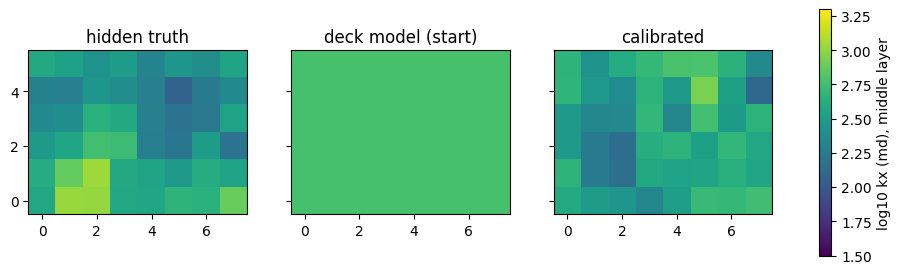

In [25]:
score = case.score_against_truth(WORK / "calibration" / "posterior_mean.json", folders["hidden"])
print(score)

truth = kusim.load_model(folders["hidden"] / "truth_model.json")
start = kusim.load_model(WORK / "model_c.json")
calibrated = kusim.load_model(WORK / "calibration" / "posterior_mean.json")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
shape = (truth.grid.nz, truth.grid.ny, truth.grid.nx)
for ax, (name, m) in zip(axes, [("hidden truth", truth), ("deck model (start)", start), ("calibrated", calibrated)]):
    image = ax.imshow(np.log10(m.kx.reshape(shape)[1]), origin="lower", vmin=1.5, vmax=3.3, cmap="viridis")
    ax.set_title(name)
fig.colorbar(image, ax=axes, label="log10 kx (md), middle layer")
plt.show()

**(d) Rewrite the claim.** A good match to the history is not proof that the model is right: there are 3 wells and 144 blocks. Here is a
claim that follows from the numbers above; compare it with the agent's `report.md`.

In [26]:
def misfit_of(model_part, data_part):
    sel = table[table.model.str.contains(model_part) & table.data.str.contains(data_part)]["misfit (RMS / sigma)"]
    return sel.iloc[-1]


print(f"""The calibrated model reproduces the history (misfit {misfit_of('calibration', 'history'):.1f}, the deck model had {misfit_of('model_c', 'history'):.0f}).
On the later data, which were not used, its misfit is {misfit_of('calibration', 'later'):.1f} (the deck model had {misfit_of('model_c', 'later'):.0f}): better than the start, but
far from 1, so the model is not yet a reliable forecaster. The error of ln kx against the truth went from
{score['deck_model']} to {score['calibrated']}: the data helped only partly. Next: more members, a different sigma, check
the residuals by well, and more data before this model is used for a decision.""")

The calibrated model reproduces the history (misfit 1.3, the deck model had 45).
On the later data, which were not used, its misfit is 12.4 (the deck model had 67): better than the start, but
far from 1, so the model is not yet a reliable forecaster. The error of ln kx against the truth went from
0.976 to 0.754: the data helped only partly. Next: more members, a different sigma, check
the residuals by well, and more data before this model is used for a decision.


**Questions.** (1) Which sentence of the agent's report is not supported by your table? (2) Which tool answer would have told the agent to
be careful, and did the system prompt tell it to look? (3) Change `SYSTEM_PROMPT` (for example add "report the misfit on the later data
next to the history misfit") and run Task C again with a live model: does the report change?

## 8. The same agent over HTTP

Everything above ran `python -m kusim ...` in a folder. The same commands are also available over **HTTP** (`kusim serve`), so an agent can drive a simulator
that runs on another machine or in a container. Only the transport changes; the tools, the checks and the answers are the same.
This needs `pip install kusim[api]` (FastAPI and uvicorn).

In [27]:
if importlib.util.find_spec("fastapi") and importlib.util.find_spec("uvicorn"):
    server = al.HttpTransport.start(al.Workspace(WORK), port=8765)          # starts `kusim serve` on this workspace folder
    try:
        plan = [{"tool_calls": [{"name": "run", "arguments": {"model": "model.json", "out": "runs/http_base"}}]}, {"text": "done"}]
        http_agent = al.Agent(al.connect("scripted", script=plan), WORK, transport=server, verbose=False, trace="trace_http.jsonl")
        http_agent.run("run model.json")
    finally:
        server.close()
    over_http = json.loads((WORK / "runs/http_base/summary.json").read_text())["wells"]["P1"]["cum_oil"]
    print(f"cumulative oil of P1: over HTTP {over_http:,.0f} STB, over the command line {base:,.0f} STB: identical = {over_http == base}")
else:
    print("FastAPI is not installed in this environment: pip install kusim[api] (or: uv add fastapi uvicorn), then run this cell again.")

cumulative oil of P1: over HTTP 107,059 STB, over the command line 107,059 STB: identical = True


## 9. Compare models (live models only)

Run the same task three times on each provider you have a key for. Runs differ (the model is not deterministic), small models fail differently from large ones:
count successes, steps and tokens instead of judging one run.

In [28]:
candidates = [p for p in ("mistral", "groq", "anthropic", "openrouter") if os.environ.get(al.PRESETS[p]["key_env"])]
rows = []
for provider in candidates:
    for attempt in range(3):
        try:
            a = al.Agent(al.connect(provider), WORK, approve=al.deny_all, verbose=False, trace=f"trace_cmp_{provider}.jsonl")
            r = a.run(sc.TASKS["A"])
            rows.append((provider, attempt, r.stopped, r.steps, sum(not c["ok"] for c in r.calls), r.tokens["input_tokens"] + r.tokens["output_tokens"]))
        except al.LLMError as problem:
            rows.append((provider, attempt, "model error: " + str(problem)[:50], 0, 0, 0))
if rows:
    display(pd.DataFrame(rows, columns=["provider", "run", "stopped", "tool calls", "failed calls", "tokens"]))
else:
    print("no provider keys set (MISTRAL_API_KEY, GROQ_API_KEY, ANTHROPIC_API_KEY, OPENROUTER_API_KEY): skipped")

no provider keys set (MISTRAL_API_KEY, GROQ_API_KEY, ANTHROPIC_API_KEY, OPENROUTER_API_KEY): skipped


## 10. Add your own tool

kusim's commands are the tools a *simulator* user needs. A real project has small helpers of its own. Giving an agent a new tool is a description plus a
Python function. Example: field data arrive in bar and m3/d, kusim wants psi and STB/day, and a model that converts in its head makes arithmetic mistakes.

In [29]:
FACTORS = {"bar": 14.5037738, "mpa": 145.037738, "kpa": 0.145037738, "atm": 14.6959488, "m3/d": 6.28981077}


def to_oilfield(value, unit):
    if unit.lower() not in FACTORS:
        return {"ok": False, "code": "unknown_unit", "error": f"unit {unit!r} is not known", "known": sorted(FACTORS)}
    return {"ok": True, "value": value * FACTORS[unit.lower()], "unit": "psi" if unit.lower() != "m3/d" else "STB/d"}


spec = {"name": "to_oilfield", "description": "Convert a pressure (bar, MPa, kPa, atm) to psi or a rate in m3/d to STB/d.",
        "parameters": {"type": "object", "properties": {"value": {"type": "number"}, "unit": {"type": "string"}}, "required": ["value", "unit"]}}

plan = [{"text": "The gauge reads 196.9 bar; kusim needs psi.", "tool_calls": [{"name": "to_oilfield", "arguments": {"value": 196.9, "unit": "bar"}}]},
        lambda m: {"text": f"196.9 bar = {sc.results(m)[-1]['value']:.0f} psi."}]
agent = al.Agent(al.connect("scripted", script=plan), WORK, extra_tools={"to_oilfield": (spec, to_oilfield)}, trace="trace_units.jsonl")
agent.run("Convert 196.9 bar to psi.");


[1] agent: The gauge reads 196.9 bar; kusim needs psi.
[1] -> to_oilfield(value=196.9, unit='bar')
      <- ok=True

[2] agent: 196.9 bar = 2856 psi.

[answered] 1 tool calls, 0 tokens in / 0 out


## 11. What made this possible

An agent is only as good as the system it drives. These parts of kusim are what made the three tasks work:

| Part of kusim | What it gave the agent |
|---|---|
| One command per capability, one JSON answer each | tools generated from the command line; answers a program can read |
| `kusim schema`, strict readers, errors with `path`, `code`, `did_you_mean` | recovery from mistakes without a human |
| `validate`, `healthy`, `diagnostics`, `dropped`, `defaults_used` | things to check before believing a number |
| Guardrail limits that the agent may lower but not raise | an agent that cannot start a week-long run by accident |
| `import-deck`, `import-history` | field-style input: an ECLIPSE-style deck and a messy table of measurements |
| `ensemble --workers` | parallel members: a calibration in seconds, not hours |
| `kusim serve` | the same commands over HTTP, for a remote simulator |
| `AGENTS.md` | the instructions written once, for any agent |

## 12. Try it yourself

1. **Prediction.** For Task A, predict the result for a bottom-hole pressure of 1500 psi, then ask the agent (`new_agent` with your own request: `new_agent("A").run("...")`).
2. **Break something.** Add a mistake to `model.json` (for example `"porossity"`), ask the agent to run it, and read how the error's `did_you_mean` is used.
3. **A tighter system prompt.** Edit `SYSTEM_PROMPT` in `agent_lab.py` so that every answer must list what was not checked. Compare reports.
4. **A new tool.** Write a tool that returns the water cut of a producer at a given day from `results.json` (`kusim run ... --out` writes it), give it to the agent, and ask for the breakthrough day.
5. **Another provider.** Change `KUSIM_LLM_PROVIDER`, restart the kernel and run Tasks A and B again. Count steps and failed calls.
6. **Gradients.** Ask a live agent to find out which parameter the history is most sensitive to (`gradient` is a tool; the files `field/parameters.json` and `obs_history.json` are ready).

**Where next.** Wrap the tools in an MCP server so that chat applications can use them; give the agent a plotting tool; keep a human at the gates that matter (units, sigma, parameters, the final claim).